# Testing differences and communicating findings

After this block you can choose a statistical test from a decision table, run the t-test, the Mann–Whitney test and the chi-square test in Python, and report every result with a confidence interval and an effect size; plan and check an A/B test; turn a correlation into a regression line; and write a finding that a non-technical reader understands, as a short report or a small Streamlit dashboard. The block serves two learning outcomes of the session: applying tests and contingency tables in Python with confidence intervals and effect sizes, and interpreting correlations as the starting point for regression.

The data are the Inside Airbnb listings of Berlin (snapshot of 26 June 2026, CC BY 4.0), downloaded once as `airbnb-v1.zip` from the course drive and unzipped into `case-study/data/` (see [case-study/README.md](../../../case-study/README.md)). We report only aggregates. Block 1 ([01-lecture-exploring-data.ipynb](01-lecture-exploring-data.ipynb)) described the prices; this block asks which differences are real, how large they are, and how to tell someone.

## Overview

| Section | What it covers |
|---|---|
| Setup | the listings, the short-stay subset, the log price, a seeded random generator |
| Comparing groups: t-test and Mann–Whitney test with confidence intervals and effect sizes | the logic of a test, a null distribution by simulation, the permutation test, what a confidence interval promises, the central limit theorem, Welch's t-test and the Mann–Whitney test, Cohen's d and the CLES, rank comparison and equivalence tests, paired data |
| Categorical data: contingency tables, chi-square and Cramér's V | the chi-square test and Cramér's V, larger tables and small expected counts, standardised residuals, odds ratio and relative risk, Fisher's exact test, a confidence interval for one proportion, McNemar's test |
| A/B tests as an application | planning (metric, MDE, α, power, sample size), power by simulation, the analysis with a sample-ratio check and a CI for the lift, peeking |
| Choosing a test from a decision table | the decision table, Kruskal–Wallis, one-way and Welch ANOVA, corrections for many tests |
| From correlation to the regression line | the least-squares line from r, R² = r², reading a log-price slope, regression plots, lowess and residual plots, one line per group |
| Communicating findings: a short report or a Streamlit dashboard | the four-part finding, one-page reports, a Streamlit dashboard and how it reruns |
| Worked example | district price gaps once room type and size are held fixed |
| Check your understanding, Exercises, Debrief | five multiple-choice questions, eight exercises in pairs, what to compare afterwards |

Every comparison in this block follows the same path, from the question to a finding the reader understands:

```mermaid
flowchart LR
    A["question:<br/>do groups differ?"] --> B["choose a test<br/>(decision table)"]
    B --> C["run it:<br/>statistic, p-value"]
    C --> D["estimate:<br/>difference with 95 % CI"]
    D --> E["effect size:<br/>d, CLES, V"]
    E --> F["a finding in units<br/>the reader understands"]
```

## Setup

The first cell moves to the repository root, so that the paths `case-study/data/...` work wherever Jupyter was started.

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

Next we load the listings, keep the short-stay listings with a price ([Session 4, block 2](../../04-data-quality/workbooks/02-lecture-outliers-transformations-and-cleaning-pipeline.ipynb): the price field of medium-term listings is not comparable) and add the log price. `rng = np.random.default_rng(0)` creates one random number generator with a fixed seed, so every simulation below gives the same result on every run.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
short = listings[listings["price"].notna() & listings["minimum_nights"].lt(28)].copy()
short["log_price"] = np.log(short["price"])
rng = np.random.default_rng(0)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
print(f"{len(listings):,} listings, {len(short):,} short-stay listings with a price")

10,221 listings, 5,302 short-stay listings with a price


## Comparing groups: t-test and Mann–Whitney test with confidence intervals and effect sizes

### The logic of a test

Block 1 previewed this logic on one correlation (*Is a correlation larger than chance?*); here it becomes the recipe for every test of the block.

Every test follows the same recipe (Downey calls it "there is only one test"):

1. Choose a **test statistic** that measures the effect, such as the difference in mean price.
2. State the **null hypothesis H₀**: a world in which the effect does not exist.
3. Work out how the statistic varies in that world, by a formula or by simulation: the **null distribution**.
4. The **p-value** is the probability, in that world, of a statistic at least as extreme as the one observed.

An everyday analogy: a court assumes innocence (H₀) and asks whether the evidence would be very surprising if the accused were innocent. A p-value is **not** the probability that H₀ is true, and it says nothing about how large the effect is. The threshold 0.05 (the **significance level α**) is a convention, to be fixed before looking at the data. Rejecting a true H₀ is a **false positive** (type I error, probability α); missing a real effect is a **false negative** (type II error); the probability of detecting a real effect of a given size is the **power**.

#### A null distribution by simulation

Written in our own words after the coin-flip example of Poldrack's *Statistical Thinking for the 21st Century* (chapter 9). Suppose a host claims their listing is booked on a "coin-flip" basis, and of 100 enquiries 70 turned into bookings. Is 70 surprising if the true chance is 50 %? We simulate the null world: many rounds of 100 fair coin flips.

Next we simulate 100,000 rounds. `rng.binomial(n, p, size)` draws the number of successes in `n` trials, `size` times; the share of rounds with 70 or more successes is a one-sided p-value. `stats.binomtest` gives the exact answer.

simulated p-value: 2e-05
exact p-value:     3.925069822796835e-05


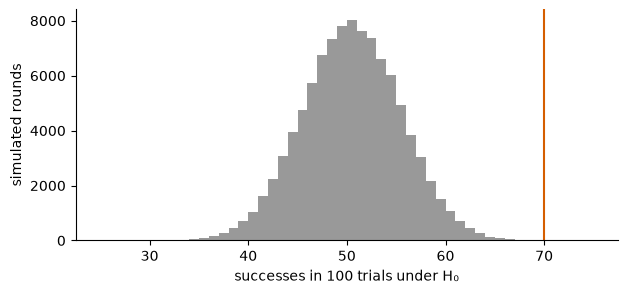

In [3]:
heads = rng.binomial(n=100, p=0.5, size=100_000)
print("simulated p-value:", (heads >= 70).mean())
print("exact p-value:    ", stats.binomtest(70, n=100, p=0.5, alternative="greater").pvalue)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(heads, bins=np.arange(25, 76), color="0.6")
ax.axvline(70, color="#D55E00")
ax.set(xlabel="successes in 100 trials under H₀", ylabel="simulated rounds")
plt.show()

**What do you see?** Where does the orange line at 70 successes sit relative to the simulated rounds?

In 100,000 simulated rounds, 70 or more successes almost never occurred: the claim of a 50 % chance does not fit the data. Simulation and formula agree; simulation has the advantage that it works for any statistic you can compute.

#### A permutation test

A **permutation test** builds the null world directly from the data. If the district did not matter for the price, the labels "Mitte" and "Neukölln" would be arbitrary: shuffling them between listings would produce differences as large as the observed one quite often.

**Predict.** If you shuffle the labels 2,000 times, how many shuffles will produce a difference in mean price as large as the observed one?

Next we run the test. `stats.permutation_test((a, b), statistic, n_resamples=..., random_state=...)` shuffles the group labels and recomputes the statistic each time.

In [4]:
mitte = short.loc[short["district"] == "Mitte", "price"].to_numpy()
neukoelln = short.loc[short["district"] == "Neukölln", "price"].to_numpy()
print(len(mitte), len(neukoelln), round(mitte.mean(), 1), round(neukoelln.mean(), 1))
res = stats.permutation_test((mitte, neukoelln), lambda a, b, axis: a.mean(axis=axis) - b.mean(axis=axis),
                             n_resamples=2_000, random_state=0)
print("observed difference:", round(res.statistic, 1), "| p-value:", res.pvalue)

1224 441 223.3 155.7
observed difference: 67.6 | p-value: 0.0009995002498750624


No shuffle came close. scipy counts the observed arrangement as one of the possible ones and adds both tails, so with 2,000 shuffles the smallest possible two-sided p-value is 2/2,001 ≈ 0.001, which is exactly what it prints. Report "p ≤ 0.001": more shuffles could show a smaller value. The test says the gap is very unlikely to be chance; it does not say why Mitte is more expensive (the section on confounding in block 1 and the worked example below).

> **Note.** Significant is not important. With large samples, tiny differences reach p < 0.05; with small samples, large differences may not. Always report the size of the effect next to the p-value. The American Statistical Association's statement on p-values (Wasserstein & Lazar, 2016) asks for estimates with intervals instead of a bare "significant / not significant".

> 📖 **Read more:** [extras/13-hypothesis-testing.ipynb](extras/13-hypothesis-testing.ipynb) (statsthinking21) and [extras/14-hypothesis-testing-by-simulation.ipynb](extras/14-hypothesis-testing-by-simulation.ipynb) (Think Stats, chapter 9): coin flips, t-tests on health survey data, simulated p-values, and permutation tests for differences in means, correlations and proportions.

### What a confidence interval promises

*The interval function is adapted from [Introduction to Probability and Statistics](https://github.com/microsoft/Data-Science-For-Beginners/blob/main/1-Introduction/04-stats-and-probability/notebook.ipynb) (Microsoft, MIT).*

A **95 % confidence interval** comes from a procedure that, in repeated samples, captures the true value 95 % of the time. Any single interval either contains the truth or not; the 95 % describes the procedure. For a mean, the interval is mean ± t × standard error, where the standard error is SD / √n and t comes from the t distribution with n − 1 degrees of freedom.

We can check the promise because we have a "population": treat the 5,302 short-stay prices as the whole city, draw many samples of 40 listings, build a 95 % interval from each, and count how often the interval contains the city mean. Next we do this 2,000 times. `stats.sem` computes the standard error; `stats.t.ppf(0.975, df)` the t value.

In [5]:
def mean_confidence_interval(data, confidence=0.95):
    a = np.asarray(data, dtype=float)
    m, se = a.mean(), stats.sem(a)
    h = se * stats.t.ppf((1 + confidence) / 2, len(a) - 1)
    return m - h, m + h

population = short["price"].to_numpy()
true_mean = population.mean()
for n in (40, 400):
    hits = [lo <= true_mean <= hi
            for lo, hi in (mean_confidence_interval(rng.choice(population, n)) for _ in range(2_000))]
    print(f"n = {n}: the interval covered the city mean in {np.mean(hits):.1%} of 2,000 samples")

n = 40: the interval covered the city mean in 88.0% of 2,000 samples


n = 400: the interval covered the city mean in 89.6% of 2,000 samples


With these heavily skewed prices the nominal 95 % is not reached, and even samples of 400 listings stay around 90 %: the t interval assumes the sample mean is roughly normal, and a few prices of several thousand euros keep its distribution skewed. The promise of a confidence interval rests on assumptions, and checking them by simulation is cheap. This is one reason to compare means on the log scale, or to use rank-based methods, for prices.

### Why the t-test works for skewed data: the central limit theorem

*Idea adapted from [Introduction to Probability and Statistics](https://github.com/microsoft/Data-Science-For-Beginners/blob/main/1-Introduction/04-stats-and-probability/notebook.ipynb) (Microsoft, MIT), applied to the Berlin prices.*

The **central limit theorem** says that the mean of many independent draws is approximately normally distributed, whatever the shape of the data, provided the sample is large enough. "Large enough" depends on the skew. Next we draw 3,000 samples each of 5, 30 and 300 listings and plot the distribution of their mean prices.

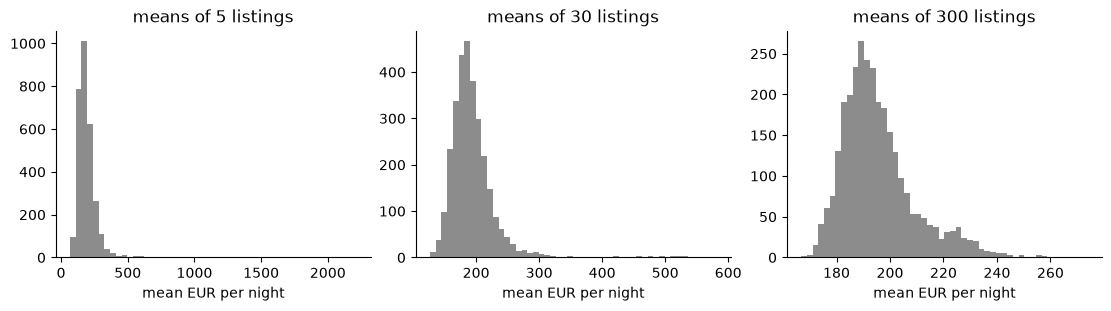

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), layout="constrained")
for ax, n in zip(axes, [5, 30, 300]):
    means = rng.choice(population, size=(3_000, n)).mean(axis=1)
    ax.hist(means, bins=50, color="0.55")
    ax.set(title=f"means of {n} listings", xlabel="mean EUR per night")
plt.show()

**What do you see?** Which panel still has a long right tail, and which looks close to a bell curve?

Means of 5 listings are still skewed; means of 300 look close to a bell curve. With the hundreds or thousands of listings per group in this block, Welch's t-test on the raw price is valid, although a few extreme prices make it noisy.

### Welch t-test and Mann–Whitney test with confidence intervals and effect sizes

- **Welch's t-test** compares two **means** without assuming equal variances. Use it by default; the equal-variance Student version is rarely needed. It relies on the sample means being approximately normal (the central limit theorem above).
- The **Mann–Whitney U test** compares **ranks**: does a random value from one group tend to exceed a random value from the other? It is robust to outliers and suits skewed data such as prices and ordinal data such as star ratings.
- If the same units are measured twice, use the **paired** versions: the paired t-test or the Wilcoxon signed-rank test (see *Paired data* below).

#### Effect sizes

An **effect size** says how large a difference is, not only whether it exists:

- the **difference in means** with its CI, in real units (euros, nights, stars): the most useful for readers;
- **Cohen's d** = difference in means / pooled SD. Rough guide: 0.2 small, 0.5 medium, 0.8 large;
- the **common-language effect size (CLES)** = U / (n₁ · n₂): the probability that a random listing from group 1 has a higher value than one from group 2 (ties count half). 0.5 means no effect. It is also called the probability of superiority.

#### One function for both tests and all effect sizes

Next we write one function that runs both tests and computes all effect sizes for two groups. `stats.ttest_ind(a, b, equal_var=False)` is Welch's test, and its result has a `.confidence_interval()` for the difference in means; `stats.mannwhitneyu(a, b)` returns U as `.statistic`.

In [7]:
def compare(df, column, group, a_value, b_value):
    # Welch t-test, Mann-Whitney U and effect sizes for two groups of one column.
    a = df.loc[df[group] == a_value, column].dropna()
    b = df.loc[df[group] == b_value, column].dropna()
    t = stats.ttest_ind(a, b, equal_var=False)
    ci = t.confidence_interval()
    mw = stats.mannwhitneyu(a, b)
    pooled_sd = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return pd.Series({"n_a": len(a), "n_b": len(b), "diff": a.mean() - b.mean(), "ci_low": ci.low,
                      "ci_high": ci.high, "p_t": t.pvalue, "p_mw": mw.pvalue,
                      "d": (a.mean() - b.mean()) / pooled_sd, "cles": mw.statistic / (len(a) * len(b))})

#### Five comparisons on the listings

**Predict.** For entire homes against private rooms, will Cohen's d and the CLES tell the same story?

Next we apply the function to five comparisons and collect the results in one table. `pd.DataFrame({...}).T` puts one comparison per row; `.map(lambda v: f"{v:.2g}")` formats the p-values, which `round` would turn into 0.

In [8]:
results = pd.DataFrame({
    "entire vs private (EUR)": compare(short, "price", "room_type", "Entire home/apt", "Private room"),
    "entire vs private (log)": compare(short, "log_price", "room_type", "Entire home/apt", "Private room"),
    "Mitte vs Neukölln (EUR)": compare(short, "price", "district", "Mitte", "Neukölln"),
    "superhost vs not (EUR)": compare(short, "price", "host_is_superhost", True, False),
    "superhost vs not (rating)": compare(listings, "review_scores_rating", "host_is_superhost", True, False),
}).T
shown = results.round({"n_a": 0, "n_b": 0, "diff": 2, "ci_low": 2, "ci_high": 2, "d": 2, "cles": 3})
shown[["p_t", "p_mw"]] = results[["p_t", "p_mw"]].map(lambda v: f"{v:.2g}")      # p-values in scientific notation
shown

,n_a,n_b,diff,ci_low,ci_high,p_t,p_mw,d,cles
entire vs private (EUR),3694.0,1483.0,112.25,102.60,121.90,1.6e-109,0,0.48,0.836
entire vs private (log),3694.0,1483.0,0.64,0.61,0.67,7.8e-301,0,1.26,0.836
Mitte vs Neukölln (EUR),1224.0,441.0,67.58,54.84,80.32,2.1e-24,2.6e-27,0.46,0.674
superhost vs not (EUR),2234.0,3056.0,7.91,-3.87,19.68,0.19,0.00016,0.03,0.530
superhost vs not (rating),2586.0,5624.0,0.14,0.13,0.15,8.5e-110,8.1e-36,0.42,0.585


Reading the results row by row:

- **Entire home against private room**: entire homes cost about €112 more per night on average, with a CI of roughly €103 to €122. Both tests agree. Cohen's d on euros is only "medium", yet the CLES says a random entire home costs more than a random private room in about 84 % of pairs. The two effect sizes disagree because a few prices in the thousands inflate the SD in the denominator of d; on the log scale d is large. For skewed data, prefer the CLES or compute d on a sensible scale.
- **Mitte against Neukölln**: about €68 more in Mitte, CLES about 0.67: a clear but overlapping difference. The test cannot say why; the worked example asks how much remains for the same room type and size.
- **Superhost or not, price**: the two tests disagree. The t-test finds no clear difference in means (its CI includes 0), the Mann–Whitney test does. Both are right about their own question: superhost listings tend to be slightly more expensive (CLES just above 0.5), but the means are dominated by a few very expensive listings, which makes the t-test noisy. Either way the effect is negligible.
- **Superhost or not, rating**: superhosts are rated about 0.14 stars higher. With a median rating of 4.86 that is a noticeable step, but superhost status is itself awarded partly for high ratings, so this comparison is close to circular.

> **Note.** The review score is an average of star ratings, bounded at 5 and crowded near the top; a t-test treats it as interval data. That is common and usually harmless with large samples, but the Mann–Whitney test, or the share of listings rated below 4.5, is easier to defend.

### Rank comparison: the probability of superiority with a confidence interval

*Adapted from [Rank comparison: two independent samples](https://www.statsmodels.org/stable/examples/notebooks/generated/stats_rankcompare.html) (statsmodels developers, BSD-3-Clause), applied to the Berlin listings.*

statsmodels provides statistics and tests for the probability that x1 has larger values than x2. Define p as the probability that a random draw from the population of the first sample has a larger value than a random draw from the population of the second sample:

p = P(x1 > x2) + 0.5 · P(x1 = x2)

This is the measure underlying the Wilcoxon–Mann–Whitney U test, the Fligner–Policello test and the Brunner–Munzel test; it is our CLES. Inference is based on the asymptotic distribution of the Brunner–Munzel test, which, unlike the Mann–Whitney test, does not assume equal shapes in the two groups. The half probability for ties corresponds to the use of midranks and makes it valid for discrete variables. The null hypothesis of stochastic equality is p = 0.5.

Next we compare the prices of superhost and other listings. `rank_compare_2indep(x1, x2)` returns a result with `.prob1` (our p), `.conf_int()` and `.test_prob_superior()`.

In [9]:
from statsmodels.stats.nonparametric import rank_compare_2indep

sup = short.loc[short["host_is_superhost"] == True, "price"].to_numpy()
other = short.loc[short["host_is_superhost"] == False, "price"].to_numpy()
rc = rank_compare_2indep(sup, other)
print("P(superhost listing more expensive):", round(rc.prob1, 3))
print("95 % CI:", np.round(rc.conf_int(), 3))
print("test of p = 0.5:", rc.test_prob_superior())

P(superhost listing more expensive): 0.53
95 % CI: [0.515 0.546]
test of p = 0.5: ProbSuperiorResult(statistic=np.float64(3.7578850821436944), pvalue=np.float64(0.0001735021903812959), df=np.float64(4549.9706410379285), distribution='t')


#### One-sided tests, non-inferiority and equivalence

The test functions take `alternative=` for one-sided tests and `value=` for a null value other than 0.5. Together they give non-inferiority tests (is a treatment at most slightly worse than a reference?) and superiority tests with a margin. An **equivalence test** (TOST, two one-sided tests) asks whether the effect lies inside an interval of values that do not matter in practice, for example 0.45 < p < 0.55; it rejects the null hypothesis "the effect is outside the interval" only if both one-sided tests reject, and its p-value is the larger of the two.

Why bother? Ordinary tests have two well-known properties, in the words of the statsmodels authors: small samples favour the null hypothesis (an underpowered study cannot reject, and non-rejection is not evidence for the null), and large samples favour the alternative (even substantively irrelevant deviations become significant). Equivalence and non-inferiority tests solve both problems by putting what we want to show into the alternative and by allowing a margin for trivial differences.

Next we test whether the superhost price effect is practically equivalent to no effect, with margins 0.45 and 0.55. `tost_prob_superior(low, upp)` returns the TOST p-value.

In [10]:
print(rc.tost_prob_superior(low=0.45, upp=0.55))

TostProbSuperiorResult(statistic=np.float64(-2.4260488629054104), pvalue=np.float64(0.007651419067659485), results_larger=ProbSuperiorResult(statistic=np.float64(9.941819027192793), pvalue=np.float64(2.3486385704722554e-23), df=np.float64(4549.9706410379285), distribution='t'), results_smaller=ProbSuperiorResult(statistic=np.float64(-2.4260488629054104), pvalue=np.float64(0.007651419067659485), df=np.float64(4549.9706410379285), distribution='t'), title='Equivalence test for Prob(x1 > x2) + 0.5 Prob(x1 = x2) ')


A small TOST p-value supports "superhost and other listings are practically equivalent in price, in the sense that neither is more expensive in more than 55 % of pairs". Here the large sample, which made the ordinary test "significant", now also supports practical equivalence: the effect is real but negligible.

> 📖 **Read more:** [extras/15-rank-comparison.ipynb](extras/15-rank-comparison.ipynb) (statsmodels documentation): the full example on ordinal treatment data, including `rank_compare_2ordinal` for frequency tables.

### Paired data: the same listing measured twice

When the same units are measured twice, the two measurements are linked: each listing is compared with itself, which removes the differences between listings. Ignoring the pairing (using an independent-samples test) wastes this information.

Do guests rate a listing's cleanliness lower than its location? Every rated listing has both scores. Next we compare them with the **paired t-test** (`stats.ttest_rel`, on the differences' mean) and the **Wilcoxon signed-rank test** (`stats.wilcoxon`, on the ranks of the differences).

In [11]:
both = listings[["review_scores_cleanliness", "review_scores_location"]].dropna()
diff = both["review_scores_cleanliness"] - both["review_scores_location"]
print(len(both), "listings | mean difference:", round(diff.mean(), 3), "| share where cleanliness is lower:",
      round((diff < 0).mean(), 3))
print("paired t-test:", stats.ttest_rel(both["review_scores_cleanliness"], both["review_scores_location"]))
print("Wilcoxon:     ", stats.wilcoxon(diff))

8217 listings | mean difference: -0.054 | share where cleanliness is lower: 0.438
paired t-test: TtestResult(statistic=np.float64(-12.643888901951653), pvalue=np.float64(2.6308850268809014e-36), df=np.int64(8216))
Wilcoxon:      WilcoxonResult(statistic=np.float64(8440968.0), pvalue=np.float64(8.6314803489671e-41))


Cleanliness scores are lower than location scores on average, and both paired tests agree. The effect in stars is small; as always, report it in units.

## Categorical data: contingency tables, chi-square and Cramér's V

### Contingency tables and the chi-square test

A **contingency table** counts observations for every combination of two categorical variables. The **chi-square test of independence** compares the observed counts O with the counts E expected if the variables were unrelated:

E = row total × column total / grand total, and χ² = Σ (O − E)² / E.

Large gaps give a large χ² and a small p-value. **Cramér's V** = √(χ² / (n · (k − 1))), with k the smaller number of rows or columns, rescales χ² to a strength between 0 (no association) and 1 (perfect association). Rough guide for k = 2: 0.1 small, 0.3 medium, 0.5 large. Most business, health and social data are categorical (plan, country, device, yes/no), and a 2 × 2 table of variant × converted is exactly the shape of an A/B test.

Do hosts with several listings fill in the licence field more often? Next we build the 2 × 2 table. `pd.crosstab(a, b)` counts the combinations; `.rename()` gives the Series readable names.

In [12]:
from scipy.stats.contingency import association

multi = listings["calculated_host_listings_count"].gt(1).rename("multi_listing_host")
entry = listings["license"].notna().rename("licence_entry")
table = pd.crosstab(multi, entry)
table

licence_entry,False,True
multi_listing_host,,
False,2330,3282
True,947,3662


**Predict.** Under independence, how many listings of multi-listing hosts would you expect to have an entry? (Row total × column total / grand total.)

Next we run the test. `stats.chi2_contingency(table)` returns χ², the p-value, the degrees of freedom and the expected counts; `association(table, method="cramer")` gives V; `normalize="index"` prints the row shares.

In [13]:
res = stats.chi2_contingency(table)
print(f"chi2 = {res.statistic:.1f}, dof = {res.dof}, p = {res.pvalue:.1e}")
print(pd.DataFrame(res.expected_freq, index=table.index, columns=table.columns).round(0))
print("Cramér's V:", round(association(table, method="cramer"), 3))
print(pd.crosstab(multi, entry, normalize="index").round(3))

chi2 = 510.0, dof = 1, p = 6.3e-113
licence_entry        False   True 
multi_listing_host                
False               1799.0  3813.0
True                1478.0  3131.0
Cramér's V: 0.224
licence_entry       False  True 
multi_listing_host              
False               0.415  0.585
True                0.205  0.795


Listings of hosts with several listings carry an entry in the licence field far more often (about 80 % against 59 %). V is small to moderate, with a clear practical meaning: registration details are more complete among professional hosts. Berlin has required a registration number for holiday rentals for years, and an EU regulation on short-term rental data (Regulation (EU) 2024/1028) applies from 20 May 2026; the data cannot tell why private hosts leave the field empty more often. Note also what the field contains: for many multi-listing hosts it is the name of a legal entity rather than a registration number (`license_status`, [Session 4, block 2](../../04-data-quality/workbooks/02-lecture-outliers-transformations-and-cleaning-pipeline.ipynb)), so "licence entry" is not the same as "registered".

> **Note.** Always print the row or column shares next to the test. The test tells you whether the table differs from independence; the shares tell you how.

### Larger tables and small expected counts

The same test works for larger tables, with (rows − 1) × (columns − 1) degrees of freedom. The chi-square approximation needs enough data in every cell: a common rule asks for expected counts of at least 5. If cells fall below, merge sparse categories, use Fisher's exact test for 2 × 2 tables (below), or report the p-value as approximate.

Next we test district × room type and count the cells with expected counts below 5. `res_big.expected_freq` holds the expected counts E.

In [14]:
big = pd.crosstab(listings["district"], listings["room_type"])
res_big = stats.chi2_contingency(big)
print(big.shape, "| dof:", res_big.dof, f"| p = {res_big.pvalue:.1e}",
      "| V:", round(association(big, method="cramer"), 3))
print("cells with expected count below 5:", (res_big.expected_freq < 5).sum(), "of", big.size)

(12, 4) | dof: 33 | p = 6.6e-36 | V: 0.091
cells with expected count below 5: 13 of 48


Highly significant, yet V is small: the room-type mix differs between districts, but not dramatically. Some cells, mostly hotel and shared rooms, have expected counts below 5, so the p-value is approximate; V is still a useful description. "Significant but small" is the typical result with thousands of observations.

### Which cells drive the result? Standardised residuals

In our own words after Poldrack's *Statistical Thinking* (chapter 12): the **standardised (Pearson) residual** of a cell is (O − E) / √E. Its square is the cell's contribution to χ². Values beyond about ±2 mark the cells that differ most from independence. Next we compute them for the district × room-type table above.

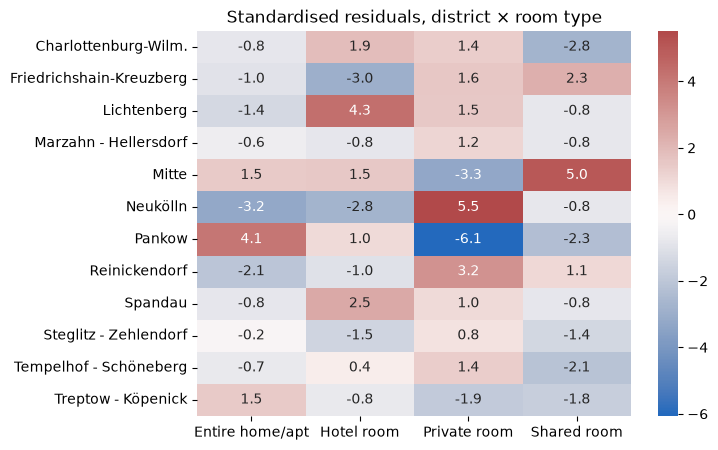

In [15]:
resid = (big - res_big.expected_freq) / np.sqrt(res_big.expected_freq)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(resid, cmap="vlag", center=0, annot=True, fmt=".1f", ax=ax)
ax.set(xlabel="", ylabel="", title="Standardised residuals, district × room type")
plt.show()

**What do you see?** Which district–room-type cells are darkest red, and what does a dark red cell mean?

Positive residuals (red) mark more listings than independence would predict, negative ones (blue) fewer. Private rooms are over-represented in Neukölln and Reinickendorf and under-represented in Pankow and Mitte; Pankow has more entire homes than independence predicts, and shared rooms cluster in Mitte and Friedrichshain-Kreuzberg.

> 📖 **Read more:** [extras/19-categorical-relationships.ipynb](extras/19-categorical-relationships.ipynb) (statsthinking21): the chi-square statistic computed by hand from expected counts on health survey data, with standardised residuals.

### Direction and size: odds ratio and relative risk

*Adapted from [Chi-square test of independence of variables in a contingency table](https://docs.scipy.org/doc/scipy/tutorial/stats/hypothesis_chi2_contingency.html) (SciPy developers, BSD-3-Clause).*

A meta-analysis of randomised trials investigated the use of aspirin to prevent cardiovascular events in women and men (Berger et al., 2006). The study notably concluded that aspirin therapy reduced the risk of a composite of cardiovascular events due to its effect on reducing the risk of ischemic stroke in women. Focus on ischemic stroke in women. Participants took aspirin or a placebo on a regular basis for several years:

|                 | Aspirin | Control/Placebo |
|-----------------|---------|-----------------|
| Ischemic stroke |    176  |        230      |
| No stroke       |  21035  |      21018      |

Is there evidence that aspirin reduces the risk of ischemic stroke? The null hypothesis H₀: the effect of aspirin is equivalent to that of placebo. Next we run the chi-square test on the table.

In [16]:
aspirin = np.array([[176, 230], [21035, 21018]])
res_asp = stats.chi2_contingency(aspirin)
print(round(res_asp.statistic, 2), round(res_asp.pvalue, 4))

6.89 0.0087


At a significance level of 5 %, we would reject the null hypothesis in favour of the alternative "the effect of aspirin is not equivalent to the effect of placebo". Because `chi2_contingency` performs a two-sided test, the alternative does not indicate the direction of the effect. The **odds ratio** does: the odds of a stroke under aspirin divided by the odds under placebo. Below 1 means aspirin lowers the odds. The **relative risk** (risk ratio) compares the probabilities directly and is easier to explain: "a stroke was x % less likely". With rare events the two are nearly equal.

Next we compute both with confidence intervals. `odds_ratio(table)` expects the table with the exposure in the columns, as here; `relative_risk(exposed_cases, exposed_total, control_cases, control_total)` takes the counts.

In [17]:
from scipy.stats.contingency import odds_ratio, relative_risk

orr = odds_ratio(aspirin)
print("odds ratio:", round(orr.statistic, 3), "95 % CI:", np.round(orr.confidence_interval(), 3))
rr = relative_risk(176, 176 + 21035, 230, 230 + 21018)
print("relative risk:", round(rr.relative_risk, 3), "95 % CI:", np.round(rr.confidence_interval(), 3))

odds ratio: 0.765 95 % CI: [0.624 0.935]
relative risk: 0.767 95 % CI: [0.631 0.932]


On the listings, a relative risk is a natural effect size for the licence table above: how much more likely is an entry for a multi-listing host? Next we compute it from the counts in `table`.

In [18]:
rr_l = relative_risk(table.loc[True, True], table.loc[True].sum(), table.loc[False, True], table.loc[False].sum())
print("relative 'risk' of a licence entry, multi vs single:", round(rr_l.relative_risk, 3),
      np.round(rr_l.confidence_interval(), 3))

relative 'risk' of a licence entry, multi vs single: 1.359 [1.323 1.395]


### Small tables: Fisher's exact test

*Adapted from [Fisher's exact test](https://docs.scipy.org/doc/scipy/tutorial/stats/hypothesis_fisher_exact.html) (SciPy developers, BSD-3-Clause).*

A meta-analysis investigated the effective dose of acetazolamide for preventing acute mountain sickness (Low et al., 2012). It concluded that 250 mg, 500 mg and 750 mg daily were all efficacious, and 250 mg was the lowest effective dose with available evidence. The table summarises an experiment in which some participants took 250 mg daily while others took a placebo:

|                         | Acetazolamide | Control/Placebo |
|-------------------------|---------------|-----------------|
| Acute mountain sickness |       7       |        17       |
| No                      |      15       |         5       |

Is there evidence that acetazolamide 250 mg reduces the risk? H₀: the odds of acute mountain sickness are the same with acetazolamide as with placebo. With such small counts the chi-square approximation is poor; **Fisher's exact test** computes the p-value exactly. Next we run it one-sided (`alternative="less"`: the odds under treatment are lower).

In [19]:
res_f = stats.fisher_exact([[7, 17], [15, 5]], alternative="less")
print("odds ratio:", round(res_f.statistic, 3), "| p-value:", round(res_f.pvalue, 5))

odds ratio: 0.137 | p-value: 0.00288


At 5 % we would reject H₀ in favour of "the odds of acute mountain sickness with acetazolamide are less than with placebo". Note: the null distribution of Fisher's test assumes that both row and column sums are fixed, so the test is conservative when applied to an experiment in which the row sums are not fixed. Here the column sums are fixed (22 subjects in each group), but the number of cases of mountain sickness is not, and cannot be, fixed before the experiment: it is a consequence. **Boschloo's test** does not depend on the assumption that the row sums are fixed, and so provides a more powerful test in this situation. Next we verify that its p-value is smaller. `stats.boschloo_exact` takes the same table.

On the listings, the same situation arises for small groups, such as the shared rooms of a single district: when expected counts fall below 5, Fisher's (or Boschloo's) test replaces the chi-square test.

In [20]:
print("Boschloo p-value:", round(stats.boschloo_exact([[7, 17], [15, 5]], alternative="less").pvalue, 5))

Boschloo p-value: 0.00151


> 📖 **Read more:** [extras/17-chi-square-contingency-test.ipynb](extras/17-chi-square-contingency-test.ipynb) and [extras/18-fisher-exact-test.ipynb](extras/18-fisher-exact-test.ipynb) (SciPy documentation): the original tutorials.

### One proportion: a confidence interval for a share

A share computed from a sample (a **proportion**) has a confidence interval too. The Wilson interval behaves well even for shares near 0 or 1. Next we compute the share of short-stay entire homes whose licence field holds a registration number. `proportion_confint(count, nobs, method="wilson")` returns the interval.

In [21]:
from statsmodels.stats.proportion import proportion_confint

entire = short[short["room_type"] == "Entire home/apt"]
k, n = (entire["license_status"] == "registration number").sum(), len(entire)
low, high = proportion_confint(k, n, method="wilson")
print(f"{k} of {n} = {k / n:.1%}, 95 % CI {low:.1%} to {high:.1%}")

1685 of 3694 = 45.6%, 95 % CI 44.0% to 47.2%


### Paired yes/no data: McNemar's test

When the same people answer a yes/no question twice (before and after a campaign, say), the 2 × 2 table of "before × after" is paired. Only the people who changed their answer carry information, and **McNemar's test** compares the two kinds of change. Next we use an invented example for illustration: 200 guests asked before and after a cleaning-fee change whether they would book again. `mcnemar(table, exact=True)` uses the exact binomial version.

In [22]:
from statsmodels.stats.contingency_tables import mcnemar

# invented numbers for illustration: rows = before (yes, no), columns = after (yes, no)
before_after = np.array([[120, 25], [10, 45]])
print(mcnemar(before_after, exact=True))

pvalue      0.016673847800120715
statistic   10.0


25 guests switched from yes to no and 10 from no to yes; McNemar asks whether such an imbalance is likely by chance if switching in both directions were equally likely. On the listings, paired yes/no data would arise if the licence field of the same listings were compared across two snapshots.

> 📖 **Read more:** [extras/16-contingency-tables-and-chi-square.ipynb](extras/16-contingency-tables-and-chi-square.ipynb) (statsintro_python, Haslwanter) adds a confidence interval for one proportion, Cochran's Q and McNemar's test.

## A/B tests as an application

### Planning an A/B test

An **A/B test** is a randomised controlled experiment. Users are randomly assigned to the current version (A, control) or the change (B, treatment). Randomisation makes the groups alike in everything else, on average, so a difference in outcome is caused by the change: it removes the confounding of block 1 (*Confounding and Simpson's paradox*). Our example: a booking platform tests a new photo gallery on its listing pages; the metric is the share of visitors who send a booking request (baseline 10 %).

Before launch, write down:

- **one primary metric** (here the booking-request rate) and **guardrail metrics** that must not get worse (page load time, cancellations);
- the **minimum detectable effect (MDE)**: the smallest lift worth acting on (here from 10 % to 11 %);
- **α** (the accepted false-positive rate, usually 5 %) and **power** (the chance of detecting the MDE if it is real, usually 80 %).

Together these determine the **sample size**.

```mermaid
sequenceDiagram
    participant P as Product team
    participant E as Experiment platform
    participant U as Users
    P->>E: metric, MDE, alpha, power -> sample size
    E->>U: random assignment to A or B
    U-->>E: booking requests per group
    E->>E: sample-ratio check, then test
    E-->>P: lift with 95 % CI and guardrails
```

Next we compute the sample size. `proportion_effectsize(0.11, 0.10)` converts the two rates into Cohen's h; `NormalIndPower().solve_power(effect_size=..., alpha=..., power=...)` returns the number of users per group.

In [23]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_effectsize, proportions_ztest

effect = proportion_effectsize(0.11, 0.10)
n_plan = int(np.ceil(NormalIndPower().solve_power(effect_size=effect, alpha=0.05, power=0.8)))
print("users per group:", n_plan)

users per group: 14745


About 15,000 visitors per group to detect a lift of one percentage point. Halving the MDE roughly quadruples the sample size, because the required n grows with 1 / effect².

### Checking the power by simulation

Power is a promise about repeated experiments: if the true lift is exactly the MDE, 80 % of experiments of the planned size will detect it. Next we check this by simulating 2,000 experiments with true rates of 10 % and 11 % and the planned size, testing each with the z-test written out in vectorised form (pooled proportion, standard error, z, two-sided p from the normal distribution).

In [24]:
def z_test_p(k_b, k_a, n_b, n_a):
    pooled = (k_b + k_a) / (n_b + n_a)
    se = np.sqrt(pooled * (1 - pooled) * (1 / n_b + 1 / n_a))
    return 2 * stats.norm.sf(np.abs((k_b / n_b - k_a / n_a) / se))

k_a = rng.binomial(n_plan, 0.10, size=2_000)
k_b = rng.binomial(n_plan, 0.11, size=2_000)
print("share of experiments with p < 0.05:", (z_test_p(k_b, k_a, n_plan, n_plan) < 0.05).mean())

share of experiments with p < 0.05: 0.792


Close to the planned 80 %: one experiment in five misses a real effect of exactly the MDE. If the true lift is smaller than the MDE, power is lower still.

### Analysing an A/B test

After the planned sample is reached, analyse once. Two checks and one estimate:

1. **Sample-ratio check**: with a planned 50/50 split, are the group sizes compatible with 50/50? A **sample-ratio mismatch** signals broken assignment or logging and invalidates the test.
2. **Two-proportion z-test** on the 2 × 2 table of variant × converted.
3. **CI for the lift** (the difference in rates), the number the product team needs.

Next we analyse simulated results. `stats.chisquare(users)` tests the split against equal expected counts; `proportions_ztest(successes, totals)` and `confint_proportions_2indep(k1, n1, k2, n2)` give the test and the CI for the difference.

In [25]:
conversions, users = [1_630, 1_480], [14_800, 14_750]          # B (new gallery), A (current page); simulated
print("sample-ratio check p =", round(stats.chisquare(users).pvalue, 3))
z, p = proportions_ztest(conversions, users)
print(f"z = {z:.2f}, p = {p:.4f}")
low, high = confint_proportions_2indep(conversions[0], users[0], conversions[1], users[1])
print(f"lift: {conversions[0] / users[0] - conversions[1] / users[1]:+.4f}, 95 % CI {low:+.4f} to {high:+.4f}")

sample-ratio check p = 0.771
z = 2.74, p = 0.0061
lift: +0.0098, 95 % CI +0.0028 to +0.0168


The split is compatible with 50/50, the new gallery raised the booking-request rate by about one percentage point, and the CI excludes 0. A report says: "The new gallery raised booking requests from 10.0 % to 11.0 % (95 % CI +0.3 to +1.7 points)", plus the guardrails.

In practice, experiments are where data roles use statistics most often. Kohavi, Tang and Xu (2020) describe experimentation platforms at Microsoft, Google and LinkedIn that run thousands of controlled experiments per year.

### Peeking

**Peeking** (an informal but common term) means checking the result every day and stopping at the first p < 0.05. Each look is another chance for noise to cross the threshold, so the false-positive rate rises far above 5 %. Next we simulate 2,000 experiments **without any effect** (both groups 10 %), look after every 1,000 users per group up to 15,000, and count how often at least one look shows p < 0.05. `cumsum(axis=1)` accumulates the conversions over the looks.

**Predict.** With 15 looks and no real effect, what share of the 2,000 experiments will show p < 0.05 at least once: about 5 %, about 10 %, or more than 20 %?

In [26]:
looks = np.arange(1, 16) * 1_000
k_a = rng.binomial(1_000, 0.10, size=(2_000, 15)).cumsum(axis=1)     # conversions up to each look
k_b = rng.binomial(1_000, 0.10, size=(2_000, 15)).cumsum(axis=1)
p_each = z_test_p(k_b, k_a, looks, looks)
print("false wins when analysing once at the end:", (p_each[:, -1] < 0.05).mean())
print("false wins when stopping at the first p < 0.05:", (p_each < 0.05).any(axis=1).mean())

false wins when analysing once at the end: 0.0535
false wins when stopping at the first p < 0.05: 0.225


Analysed once, about 5 % of no-effect experiments are false wins, as promised. With 15 peeks the rate is several times higher. Fix the sample size in advance and analyse once, or use a method designed for repeated looks (sequential testing). Airbnb's data science team described exactly this problem in its search experiments (Overgoor, 2014); Miller (2010) explains it with simulations.

## Choosing a test from a decision table

### The decision table

The choice depends on three questions: what type is the **outcome**, how many **groups** are compared, and are the groups **independent** or **paired** (the same units measured twice)?

| Outcome | Groups | Independent groups | Paired / repeated |
|---|---|---|---|
| numeric, roughly symmetric or large n | 2 | Welch t-test (`ttest_ind(equal_var=False)`) | paired t-test (`ttest_rel`) |
| numeric, skewed, small n, or ordinal | 2 | Mann–Whitney U (`mannwhitneyu`) | Wilcoxon signed-rank (`wilcoxon`) |
| numeric | 3 or more | one-way ANOVA (`f_oneway`), Welch ANOVA (`equal_var=False`) | repeated-measures ANOVA |
| ordinal or skewed | 3 or more | Kruskal–Wallis (`kruskal`) | Friedman (`friedmanchisquare`) |
| categorical | 2 or more | chi-square (`chi2_contingency`); Fisher's exact for small 2 × 2 | McNemar (2 × 2, statsmodels) |
| proportion (A/B) | 2 | two-proportion z-test (`proportions_ztest`) | McNemar |
| two numeric variables | – | Pearson r (linear) or Spearman ρ (monotonic) | – |

```mermaid
flowchart TD
    S{"Outcome type?"} -->|"numeric or ordinal"| G{"How many groups?"}
    S -->|"categorical"| P1{"Paired?"}
    S -->|"two numeric variables"| COR["Pearson r or Spearman rho"]
    P1 -->|"no"| SMALL{"Expected counts<br/>below 5?"}
    P1 -->|"yes, 2 x 2"| MCN["McNemar"]
    SMALL -->|"no"| CHI["chi-square + Cramer's V"]
    SMALL -->|"yes, 2 x 2"| FISH["Fisher's exact test"]
    G -->|"two"| P2{"Paired?"}
    G -->|"three or more"| P3{"Roughly normal<br/>or large n?"}
    P2 -->|"no"| WT["Welch t-test or<br/>Mann-Whitney U"]
    P2 -->|"yes"| PT["paired t-test or<br/>Wilcoxon signed-rank"]
    P3 -->|"yes"| AN["one-way ANOVA"]
    P3 -->|"no, or ordinal"| KW["Kruskal-Wallis"]
```

A wrong test can give a wrong answer: an independent-samples test on paired data ignores that each unit is compared with itself and loses power; a chi-square test on tiny counts gives unreliable p-values. A decision table makes the choice explicit and reviewable, before seeing the data, as statistical analysis plans of clinical trials do.

**Predict.** Which test from the table fits "does the nightly price differ between the twelve districts?"

Next we run it. `stats.kruskal(*groups)` takes one array per group; the list comprehension over `groupby` builds them.

In [27]:
groups = [g["price"].to_numpy() for _, g in short.groupby("district")]
print("Kruskal-Wallis:", stats.kruskal(*groups))
print(short.groupby("district")["price"].median().sort_values().iloc[[0, 1, -2, -1]].to_dict())

Kruskal-Wallis: KruskalResult(statistic=np.float64(322.0908371648197), pvalue=np.float64(1.9208948513302169e-62))
{'Reinickendorf': 99.5, 'Spandau': 120.5, 'Pankow': 173.5, 'Mitte': 192.04000000000002}


The district matters for the price; the medians show from where to where. The test does not say which districts differ from which; that needs pairwise comparisons, with a correction for many tests (see *Many tests* below).

### Three or more groups: ANOVA

Explained in our own words after Haslwanter's *An Introduction to Statistics with Python* (chapter 8). The **one-way analysis of variance (ANOVA)** compares the means of several groups by comparing two variances: the spread of the group means around the grand mean (between groups) and the spread of the observations within each group. If the group means differ more than the within-group spread would lead us to expect, the F statistic (between / within) is large. The classical ANOVA assumes equal variances in all groups, which the **Levene test** checks; **Welch's ANOVA** drops the assumption.

Next we run all three on the log price by room type for entire homes, private rooms and hotel rooms. `stats.levene`, `stats.f_oneway` and `stats.f_oneway(..., equal_var=False)` take one array per group.

In [28]:
three = [short.loc[short["room_type"] == r, "log_price"] for r in ["Entire home/apt", "Private room", "Hotel room"]]
print("Levene:      ", stats.levene(*three))
print("ANOVA:       ", stats.f_oneway(*three))
print("Welch ANOVA: ", stats.f_oneway(*three, equal_var=False))

Levene:       LeveneResult(statistic=np.float64(6.673122205480008), pvalue=np.float64(0.0012752238365162395))
ANOVA:        F_onewayResult(statistic=np.float64(836.6652438171767), pvalue=np.float64(4.8985172e-316))
Welch ANOVA:  F_onewayResult(statistic=np.float64(879.6555318284087), pvalue=np.float64(6.210750144809078e-89))


The same ANOVA can be written as a regression with a categorical predictor in statsmodels (`smf.ols("log_price ~ C(room_type)", data).fit()` followed by `sm.stats.anova_lm(model)`), the route Session 6 takes.

> 📖 **Read more:** [extras/20-one-way-anova.ipynb](extras/20-one-way-anova.ipynb) (statsintro_python, Haslwanter): why the spread within groups matters, the Levene test and ANOVA with scipy and statsmodels.

### Many tests: correcting p-values

Running many tests on the same data is called **multiple testing** (or the multiple-comparisons problem). At α = 0.05, each test on pure noise has a 5 % chance of a false positive; with 20 independent tests, the chance of at least one is 1 − 0.95²⁰ ≈ 64 %. When you test many metrics, subgroups or pairs, correct the p-values: **Holm** controls the chance of any false positive (family-wise error rate), **Benjamini–Hochberg** the expected share of false positives among the discoveries (false discovery rate), which is less strict.

Next we compare each district with Mitte (11 Mann–Whitney tests) and correct the p-values. `multipletests(pvals, method="holm")` returns, among others, the reject decisions and the corrected p-values.

In [29]:
from statsmodels.stats.multitest import multipletests

others = [d for d in short["district"].unique() if d != "Mitte"]
pvals = [stats.mannwhitneyu(mitte, short.loc[short["district"] == d, "price"]).pvalue for d in others]
holm = multipletests(pvals, method="holm")[1]
bh = multipletests(pvals, method="fdr_bh")[1]
print(pd.DataFrame({"p": pvals, "Holm": holm, "BH": bh}, index=others).sort_values("p").map(lambda v: f"{v:.2g}"))

                                p     Holm       BH
Neukölln                  2.6e-27  2.9e-26  2.9e-26
Treptow - Köpenick        2.6e-22  2.6e-21  1.4e-21
Reinickendorf             1.2e-19    1e-18  4.3e-19
Tempelhof - Schöneberg    1.1e-15  8.9e-15    3e-15
Lichtenberg               6.3e-14  4.4e-13  1.4e-13
Charlottenburg-Wilm.      8.9e-13  5.4e-12  1.6e-12
Friedrichshain-Kreuzberg  5.5e-12  2.7e-11  8.6e-12
Steglitz - Zehlendorf     1.4e-10  5.7e-10    2e-10
Marzahn - Hellersdorf     3.8e-07  1.1e-06  4.6e-07
Spandau                   0.00029  0.00058  0.00032
Pankow                     0.0014   0.0014   0.0014


With this much data most districts differ from Mitte even after correction; corrections matter most when effects are small and many tests are run.

## From correlation to the regression line

### The least-squares line

The **least-squares line** ŷ = b₀ + b₁·x is the straight line that minimises the sum of squared vertical distances (**residuals** y − ŷ) between the points and the line. Its slope and intercept follow directly from the correlation:

b₁ = r · s_y / s_x and b₀ = ȳ − b₁ · x̄,

where s_x and s_y are the standard deviations. The line always passes through the point of means (x̄, ȳ). In simple regression, the **R²** of the line (the share of the variance of y it explains) equals r². A small example: if r = 0.5, s_x = 2 and s_y = 10, then b₁ = 0.5 × 10 / 2 = 2.5: y rises by 2.5 units per unit of x. The correlation is symmetric in x and y; the slope is not.

![Left: a least-squares line with residuals on toy data. Right: log price against the number of guests for short-stay listings, with the mean per number of guests and the least-squares line](../figures/regression-line.png)

Next we compute the line for log price on guests by hand and check it with numpy. `np.corrcoef(x, y)[0, 1]` gives r; `np.polyfit(x, y, deg=1)` fits a straight line and returns slope and intercept.

**Predict.** The correlation between guests and log price is r = 0.603. Will the R² of the least-squares line be about 0.60, about 0.36, or about 0.78?

In [30]:
x = short["accommodates"]
y = short["log_price"]                  # natural log: coefficients read as approximate percentages
r = np.corrcoef(x, y)[0, 1]
b1 = r * y.std() / x.std()              # slope from the correlation
b0 = y.mean() - b1 * x.mean()           # line through the point of means
print("r:", round(r, 3), "| slope:", round(b1, 3), "| intercept:", round(b0, 3))
print("numpy polyfit:", np.polyfit(x, y, deg=1).round(3))
residuals = y - (b0 + b1 * x)
print("R²:", round(1 - (residuals**2).sum() / ((y - y.mean())**2).sum(), 3), "| r²:", round(r**2, 3))

r: 0.603 | slope: 0.155 | intercept: 4.521
numpy polyfit: [0.155 4.521]
R²: 0.363 | r²: 0.363


Next we translate the slope back into euros. On the natural-log scale, a slope b₁ means a price about e^b₁ − 1 higher per additional guest; `np.exp` converts predictions back to euros.

In [31]:
print(f"per additional guest: {np.exp(b1) - 1:+.1%}")
print("predicted typical price, 2 guests:", round(np.exp(b0 + b1 * 2)), "| 4 guests:", round(np.exp(b0 + b1 * 4)))

per additional guest: +16.8%
predicted typical price, 2 guests: 125 | 4 guests: 171


Each additional guest goes with a price about 17 % higher. The predictions are typical (geometric-mean) prices, not means. R² is about 0.36: the number of guests explains about a third of the variation in log price; room type, location and much else explain the rest. That is the step to Session 6: several predictors, training and test data, error metrics. The word "regression" itself comes from Galton (1886), who fitted such a line to the heights of parents and their adult children and found that the children of tall parents were, on average, less extreme ("regression towards the mean").

### Regression plots in seaborn

*Adapted from [Estimating regression fits](https://seaborn.pydata.org/tutorial/regression.html) (Michael Waskom, BSD-3-Clause), applied to the Berlin listings.*

In the spirit of Tukey, the regression plots in seaborn are primarily intended to add a visual guide that emphasises patterns during exploratory analysis; for quantitative measures of the fit, use statsmodels. Two functions draw a scatter plot and a fitted line with a 95 % confidence band: `regplot` (axes-level, accepts arrays) and `lmplot` (figure-level, needs a DataFrame, supports `hue`, `col` and `row`).

With a discrete x such as the number of guests, the plain scatter plot is not ideal. `x_jitter` adds noise to the points only (not to the fit); `x_estimator=np.mean` collapses each x value to its mean with a confidence interval. Next we draw both. We use a random sample of 2,000 listings to keep the bootstrap of the confidence band fast; `DataFrame.sample(n, random_state=0)` draws it reproducibly.

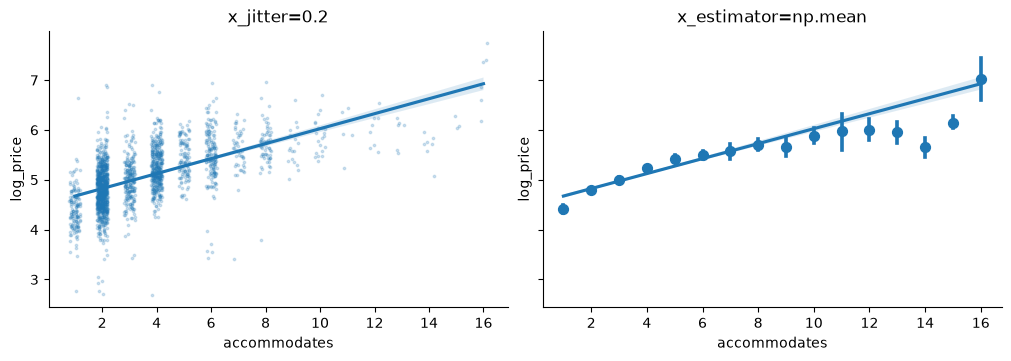

In [32]:
sample = short.sample(2_000, random_state=0)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, layout="constrained")
sns.regplot(sample, x="accommodates", y="log_price", x_jitter=0.2, scatter_kws={"s": 3, "alpha": 0.2}, ax=left)
sns.regplot(sample, x="accommodates", y="log_price", x_estimator=np.mean, ax=right)
left.set(title="x_jitter=0.2")
right.set(title="x_estimator=np.mean")
plt.show()

#### Is a straight line the right model?

Anscombe's quartet shows four datasets with the same line but very different patterns. Three tools help. `order=2` fits a polynomial; `lowess=True` fits a nonparametric local smoother with the fewest assumptions; `robust=True` down-weights large residuals. And `residplot` plots the residuals of the line against x: they should scatter randomly around zero, and any structure says the straight line misses something.

Next we compare the straight line with a lowess curve and draw the residuals.

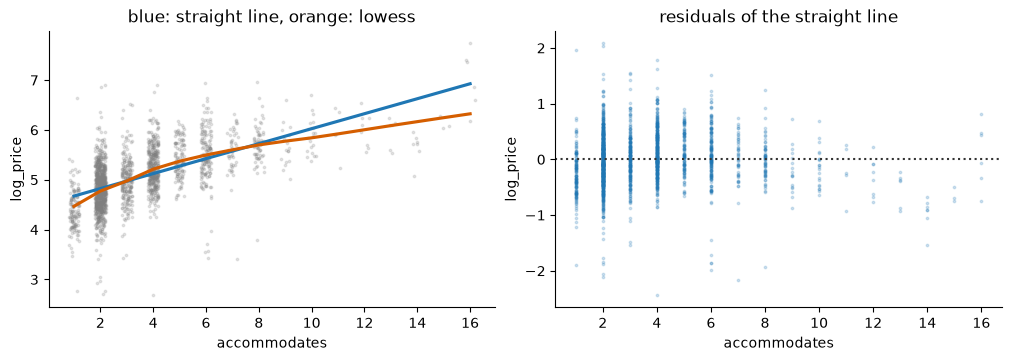

In [33]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
sns.regplot(sample, x="accommodates", y="log_price", x_jitter=0.2, ci=None,
            scatter_kws={"s": 3, "alpha": 0.2, "color": "0.5"}, ax=left)
sns.regplot(sample, x="accommodates", y="log_price", lowess=True, scatter=False,
            line_kws={"color": "#D55E00"}, ax=left)
left.set(title="blue: straight line, orange: lowess")
sns.residplot(sample, x="accommodates", y="log_price", scatter_kws={"s": 3, "alpha": 0.2}, ax=right)
right.set(title="residuals of the straight line")
plt.show()

**What do you see?** Where does the orange lowess curve leave the straight line, and where do the residuals sit below zero?

The lowess curve bends below the straight line for large listings: the price rises more slowly above about eight guests, and the residuals for the largest listings sit below zero on average.

#### Conditioning on a third variable

The more interesting question is often how the relationship changes with a third variable. `lmplot(..., hue=...)` draws one line per group on the same axes; `col=` and `row=` draw facets. Redundant coding with `markers=` keeps the plot readable in greyscale. Next we fit one line per room type.

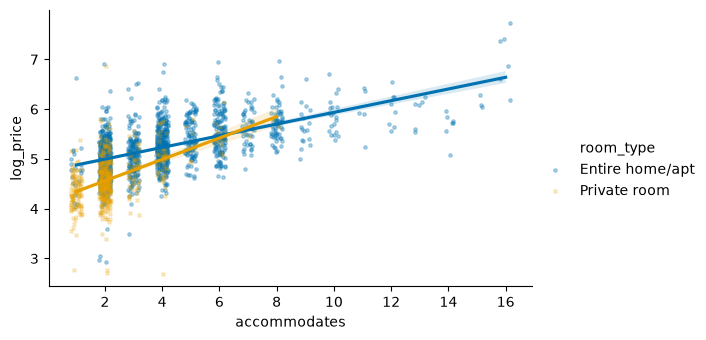

In [34]:
two = sample[sample["room_type"].isin(["Entire home/apt", "Private room"])]
g = sns.lmplot(two, x="accommodates", y="log_price", hue="room_type", markers=["o", "x"], x_jitter=0.2,
               scatter_kws={"s": 6, "alpha": 0.3}, palette=["#0072B2", "#E69F00"], height=3.5, aspect=1.6)
plt.show()

**What do you see?** Are the two room-type lines parallel, crossing or moving apart?

The lines are roughly parallel with a gap: for the same number of guests, an entire home costs more than a private room. Holding room type fixed and asking about guests is exactly what multiple regression does (Session 6).

> 📖 **Read more:** [extras/22-seaborn-regression.ipynb](extras/22-seaborn-regression.ipynb) (seaborn documentation): all regression plot options including logistic fits. [extras/21-correlation-and-simple-regression.ipynb](extras/21-correlation-and-simple-regression.ipynb) (statsintro_python, Haslwanter): the regression line solved by hand with the design matrix and with statsmodels.

## Communicating findings: a short report or a Streamlit dashboard

### A four-part finding

Most analyses reach decision makers as one chart and a few sentences. A finding that is correct but not understood has no effect. A finding for a non-technical reader follows a fixed order:

1. **the finding first**, as a full sentence;
2. **one number with its context**, in units the reader knows;
3. **what it means for the reader's decision**;
4. **one limitation**.

An example for a city housing analyst, from the Welch t-test comparison above: "Entire homes cost clearly more than private rooms. (1) A short-stay night in an entire home costs about €112 more on average, and a random entire home is more expensive than a random private room in about 84 % of pairs. (2) Any comparison of prices between districts must therefore account for the share of entire homes. (3) These are listed prices from one snapshot in June 2026, not paid prices. (4)"

A **one-page report** puts three to five such findings on a page, each with one chart. A **dashboard** gives repeated access to the same analysis with the reader's own filters, and avoids repeated one-off requests ("can you rerun this for private rooms in Pankow?"). The UK Office for National Statistics publishes statistical bulletins with the "main points" first, the same principle.

**Predict.** A user of a Streamlit dashboard moves a slider. Which code runs again: only the line with the slider, the lines after it, or the whole script from the top?

### A Streamlit dashboard

**Streamlit** turns a Python script into a web app. The script runs from top to bottom; widgets such as `st.slider` return the current user input, and `st.metric` or `st.plotly_chart` display results. Every time the user changes a widget, the whole script runs again, so expensive steps are **cached** with `@st.cache_data`. The diagram shows one round trip:

```mermaid
sequenceDiagram
    participant U as Housing analyst
    participant B as Browser
    participant S as Streamlit script
    U->>B: picks room types and guests
    B->>S: rerun with new widget values
    S->>S: load data (cached), filter
    S-->>B: metrics and charts
    B-->>U: updated page
```

The core of the course dashboard [dashboard_app.py](dashboard_app.py):

```python
import pandas as pd
import plotly.express as px
import streamlit as st

@st.cache_data                     # read the file once, not on every interaction
def load() -> pd.DataFrame:
    listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
    return listings[listings["price"].notna() & listings["minimum_nights"].lt(28)]

short = load()
st.title("Short-stay listings in Berlin: prices by district")
room_types = st.sidebar.multiselect("Room types", sorted(short["room_type"].unique()), default=["Entire home/apt"])
max_guests = st.sidebar.slider("Guests up to", 1, 16, 4)
sel = short[short["room_type"].isin(room_types) & short["accommodates"].le(max_guests)]
st.metric("Listings", f"{len(sel):,}")
by_district = sel.groupby("district", as_index=False)["price"].median().sort_values("price")
st.plotly_chart(px.bar(by_district, x="price", y="district", orientation="h"))
```

The full [dashboard_app.py](dashboard_app.py) adds a few elements worth reading:

- `st.set_page_config(page_title=..., layout="wide")` sets the browser title and uses the full width;
- `st.caption(...)` states the data source, snapshot date and the number of listings under the title, so every reader sees the data period and the number of observations;
- `st.columns(3)` lays out three `st.metric` tiles side by side (listings, median price, districts);
- a sidebar `st.slider` with a tuple default returns a range, used with `Series.between(*guests)`;
- the charts use one fixed colour per room type (the Okabe–Ito palette of block 1).

Its docstring lists three exercises (a district selectbox with neighbourhood medians, a chart of the share of entire homes, a four-part finding in a text box); exercise 2.6 below uses them. A Streamlit app can also be deployed (Streamlit Community Cloud, Hugging Face Spaces); Session 16 returns to serving a model behind such an interface.

Start it in a terminal from the repository root (not in this notebook; it runs a local web server until you stop it with Ctrl+C):

```bash
uv run streamlit run sessions/05-eda-and-statistics/workbooks/dashboard_app.py
```

The app opens at `http://localhost:8501`.

> **Note.** Dashboards spread mistakes. A wrong filter or an unlabelled axis is seen by everyone who opens the dashboard, every day. Test the numbers against a notebook, label units, and show the data period and the number of observations on the page.

## Worked example · Do district price differences survive once room type and size are held fixed?

Mitte is about €68 more expensive per night than Neukölln on average (the five comparisons above). Block 1 showed that districts differ in their mix of room types. How much of the gap is location, and how much is mix? We answer in three steps: compare like with like, test one stratum, and adjust with a regression.

### Step 1 · Compare like with like

Next we compute the median price in both districts within strata of room type and guests, keeping strata with at least 30 listings in each district. `pivot_table(index=..., columns=..., values=..., aggfunc=...)` reshapes the medians into one column per district.

In [35]:
pair = short[short["district"].isin(["Mitte", "Neukölln"]) & short["room_type"].isin(["Entire home/apt", "Private room"])]
cell = pair.groupby(["room_type", "accommodates", "district"])["price"].agg(["size", "median"]).reset_index()
wide = cell.pivot_table(index=["room_type", "accommodates"], columns="district", values=["size", "median"])
wide = wide[(wide["size"] >= 30).all(axis=1)]
wide[("median", "gap")] = wide[("median", "Mitte")] / wide[("median", "Neukölln")] - 1
wide.round(2)

median            size          median
district                       Mitte Neukölln  Mitte Neukölln    gap
room_type       accommodates                                        
Entire home/apt 2             158.45   139.90  232.0    112.0   0.13
                3             197.50   144.25  133.0     40.0   0.37
                4             215.00   165.75  181.0     60.0   0.30
Private room    1              84.50    85.21   44.0     37.0  -0.01
                2             110.96    92.00  174.0     92.0   0.21

The raw medians differ by about 44 % (€192 against €133 in block 1's district chart). Within the same room type and size, Mitte is more expensive in four of the five strata, by 13 % to 37 %; for private rooms for one guest the order even flips slightly. Comparing like with like shrinks the gap.

### Step 2 · Test one stratum

**Why this step?** Why test only one stratum, and why on the log price?

Next we compare entire homes for two guests, the largest stratum, with the `compare` function on the log price.

In [36]:
stratum = pair[(pair["room_type"] == "Entire home/apt") & (pair["accommodates"] == 2)]
res_s = compare(stratum, "log_price", "district", "Mitte", "Neukölln")
print(res_s.round(3).to_dict())
print(f"Mitte is about {np.exp(res_s['diff']) - 1:.0%} more expensive (95 % CI "
      f"{np.exp(res_s['ci_low']) - 1:.0%} to {np.exp(res_s['ci_high']) - 1:.0%})")

{'n_a': 232.0, 'n_b': 112.0, 'diff': 0.146, 'ci_low': 0.057, 'ci_high': 0.235, 'p_t': 0.001, 'p_mw': 0.001, 'd': 0.369, 'cles': 0.609}
Mitte is about 16% more expensive (95 % CI 6% to 26%)


### Step 3 · Adjust with a regression

**Why this step?** Why does Step 3 need a regression when Step 1 already compared like with like?

This step is a preview of Session 6. A regression of log price on the district alone reproduces the raw gap; adding room type and guests holds them fixed. `smf.ols(formula, data).fit()` fits the model; `C(district, Treatment("Mitte"))` makes Mitte the reference category.

In [37]:
import statsmodels.formula.api as smf

raw = smf.ols('log_price ~ C(district, Treatment("Mitte"))', data=short).fit()
adjusted = smf.ols('log_price ~ C(district, Treatment("Mitte")) + C(room_type) + accommodates', data=short).fit()
gaps = pd.DataFrame({"raw": np.exp(raw.params.filter(like="district")) - 1,
                     "same room type and guests": np.exp(adjusted.params.filter(like="district")) - 1})
gaps.index = gaps.index.str.extract(r"T\.(.*)\]")[0].rename("district")
gaps.sort_values("raw").round(3)

,raw,same room type and guests
district,,
Reinickendorf,-0.452,-0.336
Marzahn - Hellersdorf,-0.336,-0.324
Treptow - Köpenick,-0.290,-0.292
Neukölln,-0.286,-0.186
Lichtenberg,-0.273,-0.216
Tempelhof - Schöneberg,-0.235,-0.201
Steglitz - Zehlendorf,-0.231,-0.176
Spandau,-0.206,-0.109
Charlottenburg-Wilm.,-0.169,-0.081


For Neukölln, the raw gap to Mitte shrinks once room type and guests are held fixed: part of the raw difference reflects that Neukölln offers more private rooms and smaller listings. Neither number is "the" effect of the district; the adjusted one answers a different question ("for a listing of the same type and size"). Location within the district, flat quality and the share of professional hosts also vary, and the data cannot rule out further confounders.

### One-page finding for the city housing analyst

(1) A short-stay night in Mitte costs more than a comparable night in Neukölln, but less so than the raw comparison suggests. (2) In the regression, a typical short-stay night in Neukölln costs about 29 % less than in Mitte; for listings of the same room type and number of guests the gap is about 19 %, about a third smaller (table above). (3) The raw gap overstates the location premium, because Neukölln offers more private rooms and smaller listings; policy comparisons should compare like with like. (4) Listed, not paid, prices from one snapshot in June 2026; medium-term listings are excluded because their price field is not comparable.

## Check your understanding

Vote alone first, discuss with your neighbour, then vote again.

1. A test gives p = 0.03. Which statement is correct?
   - A) The null hypothesis is false with probability 97 %.
   - B) If the null hypothesis were true, data at least this extreme would occur about 3 % of the time.
   - C) The effect is large.
   - D) There is a 3 % chance that the result is due to chance.
2. For superhost against other listings, Welch's t-test gives p = 0.19 and the Mann–Whitney test p = 0.00016. What do you report?
   - A) No difference, because the t-test is the standard test.
   - B) Nothing: the result is invalid, because the two tests disagree.
   - C) A real but negligible difference: a superhost listing is more expensive in about 53 % of pairs, while a few extreme prices make the difference in means noisy.
   - D) A large difference, because one of the two tests is significant.
3. In the licence table of *Contingency tables and the chi-square test*, 2,330 listings of single-listing hosts have no licence entry. How many would you expect under independence (row total × column total / grand total)?
   - A) 1,799
   - B) 2,330
   - C) 1,478
   - D) 3,277
4. If r = −0.4, s_x = 5 and s_y = 2, what is the slope of the least-squares line?
   - A) −1.0
   - B) −0.4
   - C) +0.16
   - D) −0.16
5. Why does checking an A/B test after every 1,000 users per group and stopping at the first p < 0.05 produce more false wins than the 5 % promised?
   - A) The samples get smaller with every look.
   - B) Each look is another chance for noise to cross the threshold, and the experiment stops at the first crossing.
   - C) The z-test is not valid for proportions.
   - D) The true effect grows while the experiment runs.


## Exercises

Work in pairs; one of you types, the other directs. The lecturer chooses which exercises to set; there are more than fit into the time in class. The setup cells above (and the `compare` function of the Welch t-test section) must have run.

### 2.1 · The p-hacking machine

*Code*

> Run 20 t-tests on pure random noise. How many are "significant" at 5 %?

*Source:* [Multiple comparisons problem, Wikipedia](https://en.wikipedia.org/wiki/Multiple_comparisons_problem)

### 2.2 · The German tank problem

*Paper*

> The instructor draws five listing numbers from a hat numbered 1 to N. Estimate N.

*Source:* [German tank problem, Wikipedia](https://en.wikipedia.org/wiki/German_tank_problem)

*Your answer:*

### 2.3 · Is a registration number worth money?

*Code*

> Compare the short-stay prices of entire homes whose licence field holds a registration number with those whose field holds the name of a legal entity (`license_status`). Run Welch's t-test and the Mann–Whitney test on the log price, report the difference with its 95 % confidence interval, Cohen's d and the CLES, and write one sentence for a city housing analyst. Does the result mean that registering a flat lowers or raises its price?

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

### 2.4 · Licence entries by room type

*Code*

> Make the contingency table of `room_type` × `license_status` for all listings, with counts and row shares. Run the chi-square test and compute Cramér's V. Check the expected counts: which cells are a problem for the test, and what would you do about them? Which room type stands out?

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

### 2.5 · Plan and check an A/B test

*Code*

> A platform wants to detect a rise in the booking-request rate from 10 % to 10.5 %. How many visitors per group does it need for a power of 80 % at α = 0.05? After the test, group A has 50,600 visitors and group B 49,400, although the split was meant to be 50/50. Is that a problem?

*Source:* original exercise for this course; background: [Kohavi, Tang & Xu (2020), *Trustworthy Online Controlled Experiments*](https://experimentguide.com/)

### 2.6 · A one-page finding or a dashboard

*Pairs*

*Stretch:*

> Either write the four-part finding (finding, number, meaning, limitation) for the result of exercise 2.3 or 2.4, with one chart; or implement exercise 1 or 2 from the docstring of [dashboard_app.py](dashboard_app.py) and start the app from the repository root in a terminal with `uv run streamlit run sessions/05-eda-and-statistics/workbooks/dashboard_app.py`.

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

*Your answer:*

### 2.7 · Reorder the licence test

*Parsons*

> The lines below build the licence table of *Contingency tables and the chi-square test*, test it, and report the effect size and the row shares. Put them in a working order.
>
> ```python
> print("Cramér's V:", round(association(table, method="cramer"), 3))
> table = pd.crosstab(multi, entry)
> res = stats.chi2_contingency(table)
> multi = listings["calculated_host_listings_count"].gt(1).rename("multi_listing_host")
> print(pd.crosstab(multi, entry, normalize="index").round(3))
> entry = listings["license"].notna().rename("licence_entry")
> print(f"chi2 = {res.statistic:.1f}, dof = {res.dof}, p = {res.pvalue:.1e}")
> ```

*Source:* original exercise for this course, after the section *Contingency tables and the chi-square test*

*Your answer:*

### 2.8 · Cleanliness against location

*Find the bug*

> This cell runs and prints a p-value, but it uses the wrong test for these data. What is wrong, and which line would you write instead?
>
> ```python
> both = listings[["review_scores_cleanliness", "review_scores_location"]].dropna()
> print(stats.ttest_ind(both["review_scores_cleanliness"], both["review_scores_location"], equal_var=False))
> ```

*Source:* original exercise for this course, after the section *Paired data: the same listing measured twice*

*Your answer:*

## Debrief

- **Compare** two reports of the registration comparison (2.3) and two chi-square results (2.4). Does each report give a number in units, a CI and an effect size, not just a p-value?
- **Typical mistakes:** a causal reading of 2.3 ("registering lowers the price"), when listings with a company name are run by professional operators with other flats; a chi-square test reported without its effect size or with cells whose expected count is below 5; in 2.1, forgetting that about one "significant" result in 20 is exactly what α = 0.05 promises; in 2.5, ignoring a sample-ratio mismatch because "the difference is only 1,200 visitors".
- **Bridge to Session 6:** the regression line and the adjusted district gaps of the worked example are the first models. Session 6 adds several predictors, training and test data, and error metrics, with the same listings.

## Further reading

- Downey, A. B. (2025). *Think Stats* (3rd ed.), chapter 9 "Hypothesis testing". <https://allendowney.github.io/ThinkStats/chap09.html>
- Poldrack, R. A. (2023). *Statistical Thinking for the 21st Century*, chapters 9–12. <https://statsthinking21.github.io/statsthinking21-core-site/>
- Haslwanter, T. (2022). *An Introduction to Statistics with Python* (2nd ed.). Springer. Code: <https://github.com/thomas-haslwanter/statsintro_python>
- Wasserstein, R. L., & Lazar, N. A. (2016). The ASA statement on p-values: Context, process, and purpose. *The American Statistician*, 70(2), 129–133. <https://doi.org/10.1080/00031305.2016.1154108>
- Kohavi, R., Tang, D., & Xu, Y. (2020). *Trustworthy Online Controlled Experiments: A Practical Guide to A/B Testing*. Cambridge University Press. <https://experimentguide.com/>
- Miller, E. (2010). *How not to run an A/B test*. <https://www.evanmiller.org/how-not-to-run-an-ab-test.html>
- Overgoor, J. (2014). *Experiments at Airbnb*. Airbnb Engineering & Data Science blog. <https://medium.com/airbnb-engineering/experiments-at-airbnb-e2db3abf39e7>
- Berger, J. S., et al. (2006). Aspirin for the primary prevention of cardiovascular events in women and men: a sex-specific meta-analysis of randomized controlled trials. *JAMA*, 295(3), 306–313. <https://doi.org/10.1001/jama.295.3.306>
- Low, E. V., et al. (2012). Identifying the lowest effective dose of acetazolamide for the prophylaxis of acute mountain sickness: systematic review and meta-analysis. *BMJ*, 345, e6779. <https://doi.org/10.1136/bmj.e6779>
- Galton, F. (1886). Regression towards mediocrity in hereditary stature. *Journal of the Anthropological Institute*, 15, 246–263.
- Regulation (EU) 2024/1028 on data collection and sharing relating to short-term accommodation rental services. <https://eur-lex.europa.eu/eli/reg/2024/1028/oj>
- statsmodels developers. *Rank comparison: two independent samples*. <https://www.statsmodels.org/stable/examples/notebooks/generated/stats_rankcompare.html>
- SciPy developers. *Hypothesis tests and related functions* (tutorials). <https://docs.scipy.org/doc/scipy/tutorial/stats/hypothesis_tests.html>
- Waskom, M. *Estimating regression fits* (seaborn tutorial). <https://seaborn.pydata.org/tutorial/regression.html>
- Streamlit. *Get started: tutorials*. <https://docs.streamlit.io/get-started/tutorials>
- Extras of this block: [extras/13](extras/13-hypothesis-testing.ipynb) to [extras/22](extras/22-seaborn-regression.ipynb); provenance in [extras/README.md](extras/README.md).

*Course team · Licence: CC BY 4.0. Sections marked "Adapted from" contain text and code from the statsmodels (BSD-3-Clause), SciPy (BSD-3-Clause), seaborn (BSD-3-Clause) and Microsoft Data Science for Beginners (MIT) documentation, edited and applied to the Berlin listings. Sections written "in our own words" follow ideas from non-commercial or share-alike sources (Think Stats, Statistical Thinking for the 21st Century, statsintro_python) without copying their text.*